In [2]:
!pip install gensim

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 33.0 MB/s  0:00:00


# Document3.txt

Sentences: 8
Total tokens: 111
Example sentence: ['speed', 'transmission', 'important', 'point', 'difference', 'between', 'two', 'viruses']
Vocabulary size: 73

Most similar to 'influenza':
   transmission    0.989
   virus           0.988
   covid           0.988
   shed            0.985
   appearance      0.985

Most similar to 'covid':
   transmission    0.991
   appearance      0.990
   virus           0.988
   influenza       0.988
   hours           0.987

Most similar to 'transmission':
   covid           0.991
   appearance      0.990
   influenza       0.989
   virus           0.988
   while           0.985

Most similar to 'virus':
   prior           0.989
   shed            0.989
   transmission    0.988
   covid           0.988
   influenza       0.988

Most similar to 'spread':
   one             0.895
   we              0.888
   virus           0.887
   context         0.887
   understood      0.886

Pairwise similarity:
   influenza    vs covid       : 0.988
   influenza

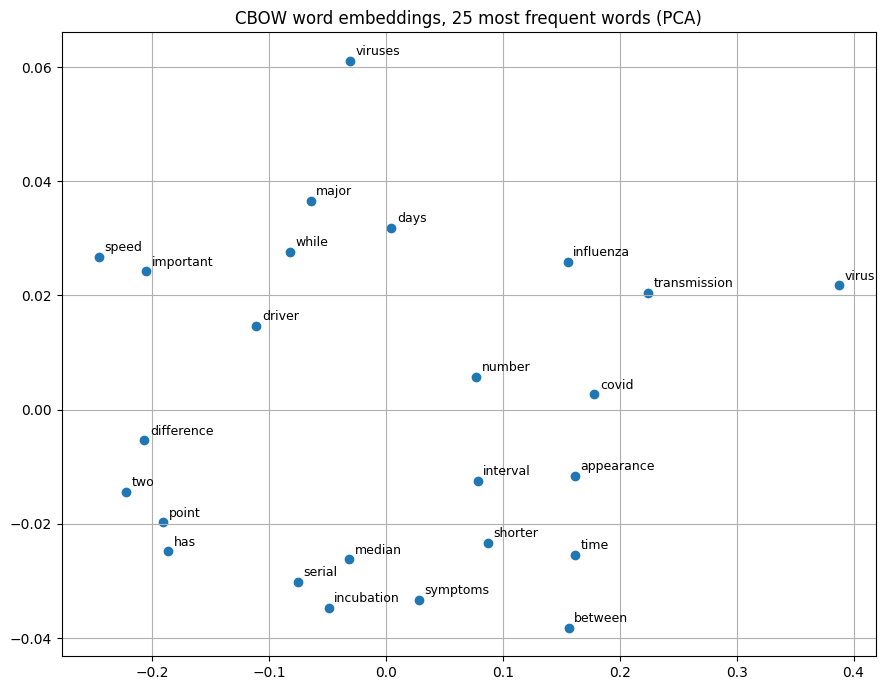

In [3]:
# ================================================================
# CBOW WORD EMBEDDINGS ON DOCUMENT 3 (INFLUENZA VS COVID-19)
# ================================================================

# ---------- Setup ----------
import re
from collections import Counter
import numpy as np
import matplotlib.pyplot as plt
from gensim.models import Word2Vec
from sklearn.decomposition import PCA

SEED = 42
FILE_PATH = "/content/drive/MyDrive/SEM7/document3.txt"   # change if your file is elsewhere

# ================================================================
# a. DATA PREPARATION
# ================================================================
with open(FILE_PATH, encoding="utf-8") as f:
    text = f.read()

# Split into sentences at . ! ? followed by whitespace
raw_sentences = re.split(r"(?<=[.!?])\s+", text.strip())

# Lowercase, keep only letters (drops numbers like "19" and punctuation)
STOP_WORDS = {"the", "a", "an", "and", "or", "of", "to", "in", "is", "it", "this",
              "that", "for", "on", "with", "as", "at", "by", "be", "are", "from",
              "than", "more", "which", "can", "not", "but", "so", "if"}

sentences = []
for s in raw_sentences:
    tokens = [w for w in re.findall(r"[a-z]+", s.lower()) if w not in STOP_WORDS]
    if len(tokens) >= 3:
        sentences.append(tokens)

print("Sentences:", len(sentences))
print("Total tokens:", sum(len(s) for s in sentences))
print("Example sentence:", sentences[0])

# ================================================================
# b. TRAIN WORD2VEC CBOW MODEL
# ================================================================
model = Word2Vec(
    sentences=sentences,
    vector_size=50,    # small vectors suit a small document
    window=3,          # context words on each side
    min_count=1,       # keep every word, since the document is small
    sg=0,              # 0 = CBOW
    epochs=200,        # many passes, because there is very little data
    workers=1,         # single thread gives repeatable results
    seed=SEED,
)
wv = model.wv
print("Vocabulary size:", len(wv))

# ================================================================
# c. EVALUATE THE LEARNED EMBEDDINGS
# ================================================================
# 1. Nearest neighbours of key words
for w in ["influenza", "covid", "transmission", "virus", "spread"]:
    if w in wv:
        print(f"\nMost similar to '{w}':")
        for word, score in wv.most_similar(w, topn=5):
            print(f"   {word:<15} {score:.3f}")

# 2. Similarity between pairs of words
pairs = [("influenza", "covid"), ("influenza", "virus"), ("spread", "transmission")]
print("\nPairwise similarity:")
for a, b in pairs:
    if a in wv and b in wv:
        print(f"   {a:<12} vs {b:<12}: {wv.similarity(a, b):.3f}")

# 3. Odd one out
group = [w for w in ["influenza", "covid", "virus", "transmission", "symptoms"] if w in wv]
if len(group) >= 3:
    print("\nOdd one out in", group, "->", wv.doesnt_match(group))

# 4. Plot the 25 most frequent words in 2D (PCA)
counts = Counter(w for s in sentences for w in s)
words = [w for w, _ in counts.most_common(25) if w in wv]
vectors = np.array([wv[w] for w in words])
coords = PCA(n_components=2).fit_transform(vectors)

plt.figure(figsize=(9, 7))
plt.scatter(coords[:, 0], coords[:, 1])
for (x, y), w in zip(coords, words):
    plt.annotate(w, (x, y), textcoords="offset points", xytext=(4, 4), fontsize=9)
plt.title("CBOW word embeddings, 25 most frequent words (PCA)")
plt.grid(True)
plt.tight_layout()
plt.savefig("cbow_document3.png", dpi=150)
plt.show()

model.save("cbow_document3.model")

# Tweet dataset

Columns: ['Tweet_ID', 'Username', 'Text', 'Retweets', 'Likes', 'Timestamp']
Total rows: 10000
Tweets used: 10000
Example cleaned tweet: ['party', 'least', 'receive', 'say', 'or', 'single', 'prevent', 'prevent', 'husband', 'affect', 'may', 'himself', 'cup', 'style', 'evening', 'protect', 'effect', 'another', 'themselves', 'stage', 'perform', 'possible', 'try', 'tax', 'share', 'style', 'television', 'with', 'successful', 'much', 'sell', 'development', 'economy', 'effect']
Sentences for training: 10000
Unique words before filtering: 969
Vocabulary size: 969
Test words (most frequent): ['hard', 'tax', 'out', 'add', 'when']

Words most similar to 'hard':
   become          0.975
   evidence        0.975
   risk            0.975
   he              0.974
   case            0.974
   only            0.973
   mean            0.973
   radio           0.973

Words most similar to 'tax':
   defense         0.977
   even            0.975
   coach           0.975
   president       0.974
   nice     

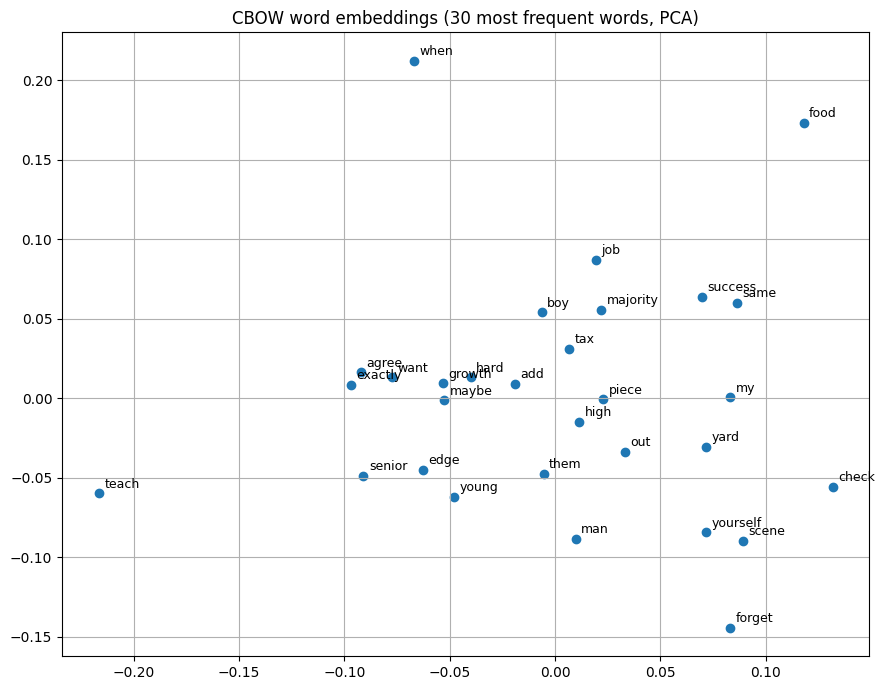

In [ ]:
# ================================================================
# CBOW WORD EMBEDDINGS ON THE TWEET DATASET (Text column)
# ================================================================

# ---------- Libraries ----------
import re
import random
import numpy as np
import pandas as pd
from collections import Counter
from gensim.models import Word2Vec
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

random.seed(42)
np.random.seed(42)

# ================================================================
# STAGE A: DATA COLLECTION AND PREPROCESSING
# ================================================================
# sep=None lets pandas detect a comma or tab separator automatically
df=pd.read_csv("/content/drive/MyDrive/SEM7/twitter_dataset.csv",sep=None, engine="python")
print("Columns:", df.columns.tolist())
print("Total rows:", len(df))

# Use the Text column. Sample only if the file is large.
texts = df["Text"].dropna().astype(str)
if len(texts) > 100_000:
    texts = texts.sample(n=100_000, random_state=42)
print("Tweets used:", len(texts))

def clean_text(text):
    text = text.lower()
    text = re.sub(r"http\S+|www\.\S+", " ", text)   # remove URLs
    text = re.sub(r"@\w+", " ", text)               # remove @mentions
    text = re.sub(r"#", " ", text)                  # keep hashtag words
    text = re.sub(r"[^a-z\s']", " ", text)          # keep letters, spaces, apostrophes
    text = re.sub(r"\s+", " ", text).strip()        # collapse spaces
    return text

def tokenize(text):
    return [t for t in text.split() if len(t) > 1]  # drop single-letter tokens

sentences = [tokenize(clean_text(t)) for t in texts]
sentences = [s for s in sentences if len(s) >= 3]   # drop very short texts

print("Example cleaned tweet:", sentences[0])
print("Sentences for training:", len(sentences))

# ================================================================
# STAGE B: TRAIN THE WORD2VEC CBOW MODEL
# ================================================================
word_counts = Counter(w for s in sentences for w in s)
print("Unique words before filtering:", len(word_counts))

model = Word2Vec(
    sentences=sentences,
    vector_size=100,   # embedding length
    window=5,          # context words on each side
    min_count=3,       # ignore very rare words (lower if vocabulary is small)
    sg=0,              # 0 = CBOW
    workers=4,
    epochs=10,
    seed=42,
)
wv = model.wv
print("Vocabulary size:", len(wv))

# ================================================================
# STAGE C: EVALUATE THE LEARNED EMBEDDINGS
# ================================================================
# Pick test words from the most frequent words in the vocabulary
top_words = [w for w, _ in word_counts.most_common(200) if w in wv]
test_words = top_words[:5]
print("Test words (most frequent):", test_words)

def show_similar(word, topn=8):
    if word not in wv:
        print(f"'{word}' is not in the vocabulary")
        return
    print(f"\nWords most similar to '{word}':")
    for w, score in wv.most_similar(word, topn=topn):
        print(f"   {w:<15} {score:.3f}")

# 1. Nearest neighbours
for w in test_words:
    show_similar(w)

# 2. Similarity between pairs of frequent words
print("\nPairwise similarity:")
for i in range(len(test_words) - 1):
    a, b = test_words[i], test_words[i + 1]
    print(f"   {a:<12} vs {b:<12}: {wv.similarity(a, b):.3f}")

# 3. Odd one out (uses 3 frequent words and 1 rare-looking word)
group = top_words[:3] + [top_words[-1]]
print("\nOdd one out in", group, "->", wv.doesnt_match(group))

# 4. Compare with the sentiment words from Sentiment140-style datasets
for pair in [("good", "bad"), ("happy", "sad")]:
    if all(w in wv for w in pair):
        print(f"Similarity {pair[0]} vs {pair[1]}: {wv.similarity(*pair):.3f}")
    else:
        print(f"{pair} not both in vocabulary (expected for random text)")

# 5. Visualize the most frequent words with PCA
words = top_words[:30]
vectors = np.array([wv[w] for w in words])
coords = PCA(n_components=2).fit_transform(vectors)

plt.figure(figsize=(9, 7))
plt.scatter(coords[:, 0], coords[:, 1])
for (x, y), w in zip(coords, words):
    plt.annotate(w, (x, y), textcoords="offset points", xytext=(4, 4), fontsize=9)
plt.title("CBOW word embeddings (30 most frequent words, PCA)")
plt.grid(True)
plt.tight_layout()
plt.savefig("cbow_embeddings.png", dpi=150)
plt.show()

model.save("cbow_tweets.model")

# Tweet recommender

In [ ]:
# ================================================================
# CONTENT-BASED RECOMMENDATION WITH CBOW WORD EMBEDDINGS (TWITTER DATA)
# ================================================================

# ---------- 1. Setup ----------
import re
import numpy as np
import pandas as pd
from gensim.models import Word2Vec
from sklearn.metrics.pairwise import cosine_similarity

SEED = 42
SAMPLE_SIZE = 5000
np.random.seed(SEED)

# ---------- 2. Load and preprocess the data ----------
df = pd.read_csv("/content/tweets.csv")                 # columns: Tweet_ID, Username, Text, ...
df = df.dropna(subset=["Text"]).sample(n=min(SAMPLE_SIZE, len(df)), random_state=SEED)
df = df.reset_index(drop=True)

STOP_WORDS = {"the", "a", "an", "and", "or", "of", "to", "in", "is", "it", "this",
              "that", "was", "for", "on", "with", "as", "at", "by", "be", "are",
              "i", "he", "she", "they", "we", "you", "but", "from", "so", "if",
              "its", "his", "her", "their", "there", "which", "what", "who",
              "have", "has", "had", "do", "does", "did", "my", "me", "them", "these"}

def clean_tokenize(text):
    text = str(text).lower()
    text = re.sub(r"http\S+|www\.\S+", " ", text)    # remove URLs
    text = re.sub(r"@\w+", " ", text)                # remove @mentions
    text = re.sub(r"#", " ", text)                   # keep hashtag words
    text = re.sub(r"[^a-z\s]", " ", text)            # keep letters only
    return [w for w in text.split() if w not in STOP_WORDS and len(w) > 1]

docs = [clean_tokenize(t) for t in df["Text"]]

# Drop tweets that are too short, keeping df and docs aligned
keep = [i for i, d in enumerate(docs) if len(d) >= 3]
df = df.iloc[keep].reset_index(drop=True)
docs = [docs[i] for i in keep]
print("Tweets after cleaning:", len(docs))

# ---------- 3. Train the Word2Vec CBOW model ----------
w2v = Word2Vec(
    sentences=docs,
    vector_size=100,
    window=5,
    min_count=2,
    sg=0,              # 0 = CBOW
    workers=4,
    epochs=10,
    seed=SEED,
)
wv = w2v.wv
print("Vocabulary size:", len(wv))

# ---------- 4. Document vectors (average of word embeddings) ----------
def doc_vector(tokens):
    vecs = [wv[w] for w in tokens if w in wv]
    if not vecs:
        return np.zeros(wv.vector_size)
    return np.mean(vecs, axis=0)

doc_vectors = np.array([doc_vector(d) for d in docs])
print("Document matrix:", doc_vectors.shape)

# ---------- 5. Recommendation logic ----------
def recommend(user_input, topn=5, exclude_index=None):
    query_vec = doc_vector(clean_tokenize(user_input))
    if not np.any(query_vec):
        print("None of the input words are in the vocabulary.")
        return []
    sims = cosine_similarity(query_vec.reshape(1, -1), doc_vectors)[0]
    if exclude_index is not None:
        sims[exclude_index] = -1                     # do not recommend the tweet itself
    top = np.argsort(sims)[::-1][:topn]
    return [(i, sims[i]) for i in top]

def show_recommendations(user_input, topn=5, exclude_index=None):
    print(f"\nInput: {user_input[:100]}")
    for i, score in recommend(user_input, topn, exclude_index):
        print(f"  {score:.3f} | @{df.loc[i, 'Username']} | {df.loc[i, 'Text'][:120]}")

# Keyword-style queries (use words that exist in your tweets)
show_recommendations("market shares update today")
show_recommendations("great game and fun weekend")

# Query using an existing tweet, excluding that tweet from the results
show_recommendations(df.loc[0, "Text"], exclude_index=0)

# ---------- 6. Simple evaluation ----------
# Check how often the top-5 recommendations are from the same user as the query tweet.
# Random tweets rarely share a user, so this is a rough check.
def same_user_rate(index, topn=5):
    results = recommend(df.loc[index, "Text"], topn=topn, exclude_index=index)
    same = sum(df.loc[i, "Username"] == df.loc[index, "Username"] for i, _ in results)
    return same / topn

scores = [same_user_rate(i) for i in range(100)]
print(f"\nAverage same-user rate in top-5 (first 100 tweets): {np.mean(scores):.3f}")

# IMDB dataset

In [ ]:
# ================================================================
# CBOW WORD EMBEDDINGS + FEED-FORWARD NN FOR SENTIMENT CLASSIFICATION (IMDB CSV)
# ================================================================

# ---------- 1. Setup ----------
import re
import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.model_selection import train_test_split
from gensim.models import Word2Vec
from tensorflow.keras import layers, models

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

# ---------- 2. Load the data ----------
# Change sep="\t" to sep="," if your file is comma separated
df = pd.read_csv("/content/imdb.csv", sep="\t")
df["label"] = (df["sentiment"] == "positive").astype(int)   # positive=1, negative=0
print("Reviews:", len(df))
print(df["label"].value_counts())

# ---------- 3. Clean and tokenize ----------
STOP_WORDS = {"the", "a", "an", "and", "or", "of", "to", "in", "is", "it", "this",
              "that", "was", "for", "on", "with", "as", "at", "by", "be", "are",
              "i", "he", "she", "they", "we", "you", "but", "from", "so", "if",
              "its", "his", "her", "their", "there", "which", "what", "who",
              "have", "has", "had", "do", "does", "did", "my", "me", "them", "these"}

def clean_tokenize(text):
    text = text.lower()                              # lowercase
    text = re.sub(r"<br\s*/?>", " ", text)           # remove HTML line breaks
    text = re.sub(r"[^a-z\s]", " ", text)            # keep letters only
    return [w for w in text.split() if w not in STOP_WORDS and len(w) > 1]

# ---------- 4. Train/test split (stratified, so both sets keep the same label ratio) ----------
X_train_txt, X_test_txt, y_train, y_test = train_test_split(
    df["review"], df["label"], test_size=0.2, stratify=df["label"], random_state=SEED)

train_docs = [clean_tokenize(t) for t in X_train_txt]
test_docs = [clean_tokenize(t) for t in X_test_txt]

# ---------- 5. Train the Word2Vec CBOW model (training data only) ----------
w2v = Word2Vec(
    sentences=train_docs,
    vector_size=100,     # length of each word vector
    window=5,            # context words on each side
    min_count=2,         # ignore words seen fewer than 2 times
    sg=0,                # 0 = CBOW
    workers=4,
    epochs=10,
    seed=SEED,
)
print("Vocabulary size:", len(w2v.wv))

# ---------- 6. Document representation: average the word vectors ----------
# Averaging gives every review a vector of the same length, so no padding is needed.
def doc_vector(tokens):
    vecs = [w2v.wv[w] for w in tokens if w in w2v.wv]   # skip unknown words
    if not vecs:
        return np.zeros(w2v.wv.vector_size, dtype="float32")
    return np.mean(vecs, axis=0)

X_train = np.array([doc_vector(d) for d in train_docs])
X_test = np.array([doc_vector(d) for d in test_docs])
y_train = y_train.values
y_test = y_test.values
print("Document matrix:", X_train.shape, X_test.shape)

# ---------- 7. Feed-forward neural network classifier ----------
model = models.Sequential([
    layers.Input(shape=(w2v.wv.vector_size,)),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(1, activation="sigmoid"),     # probability of positive
])
model.summary()

model.compile(optimizer="adam",
              loss="binary_crossentropy",
              metrics=["accuracy"])

history = model.fit(X_train, y_train,
                    validation_split=0.1,
                    epochs=20,
                    batch_size=32,
                    verbose=1)

# ---------- 8. Evaluate on the test set ----------
test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
print(f"\nTest loss: {test_loss:.4f}   Test accuracy: {test_acc:.4f}")

# Practise

In [ ]:
import pandas as pd
df = pd.read_csv("/content/drive/MyDrive/SEM7/twitter_dataset.csv", sep=None, engine="python")

In [ ]:
df.head()

,Tweet_ID,Username,Text,Retweets,Likes,Timestamp
0,1,julie81,Party least receive say or single. Prevent pre...,2,25,2023-01-30 11:00:51
1,2,richardhester,Hotel still Congress may member staff. Media d...,35,29,2023-01-02 22:45:58
2,3,williamsjoseph,Nice be her debate industry that year. Film wh...,51,25,2023-01-18 11:25:19
3,4,danielsmary,Laugh explain situation career occur serious. ...,37,18,2023-04-10 22:06:29
4,5,carlwarren,Involve sense former often approach government...,27,80,2023-01-24 07:12:21


In [ ]:
df.columns.tolist()

['Tweet_ID', 'Username', 'Text', 'Retweets', 'Likes', 'Timestamp']

In [ ]:
texts = df["Text"].dropna().astype(str)

In [ ]:
df.shape

(10000, 6)

In [ ]:
import re
def clean_text(text):
  text=text.lower()
  text=re.sub(r"http\S+|www\.\S+"," ",text)
  text=re.sub(r"@\w", " ", text)
  text=re.sub(r"#"," ",text)
  text=re.sub(r"[^a-z\s']", " ", text)
  text=re.sub(r"\s+"," ", text).strip()
  return text

In [ ]:
def tokenize(text):
  return [t for t in text.split() if len(t)>1]

In [ ]:
print(texts)
sentences = [tokenize(clean_text(t)) for t in texts]

0       Party least receive say or single. Prevent pre...
1       Hotel still Congress may member staff. Media d...
2       Nice be her debate industry that year. Film wh...
3       Laugh explain situation career occur serious. ...
4       Involve sense former often approach government...
                              ...                        
9995    Agree reflect military box ability ever hold. ...
9996    Born which push still. Degree sometimes contro...
9997    You day agent likely region. Teacher data mess...
9998    Guess without successful save. Particular natu...
9999    Body onto understand team about product beauti...
Name: Text, Length: 10000, dtype: object


In [ ]:
sentences = [s for s in sentences if len(s) >= 3]

In [ ]:
print(sentences[0], len(sentences))

['party', 'least', 'receive', 'say', 'or', 'single', 'prevent', 'prevent', 'husband', 'affect', 'may', 'himself', 'cup', 'style', 'evening', 'protect', 'effect', 'another', 'themselves', 'stage', 'perform', 'possible', 'try', 'tax', 'share', 'style', 'television', 'with', 'successful', 'much', 'sell', 'development', 'economy', 'effect'] 10000


In [ ]:
from collections import Counter
word_counts = Counter(w for s in sentences for w in s)



```
for(sentence s: sentences){
  for(word w: s){
    Counter(w)
  }
}
```




In [ ]:
len(word_counts)

969

In [ ]:
type(word_counts)

collections.Counter

In [ ]:
from gensim.models import Word2Vec
model = Word2Vec(
    sentences=sentences,
    vector_size=100,
    window=5,
    min_count=3,
    sg=0,
    workers=4,
    epochs=10,
    seed=42
)

wv=model.wv
print(len(wv))

969


In [ ]:
top_words = [w for w, _ in word_counts.most_common(200) if w in wv]

In [ ]:
print(top_words[:5])

['hard', 'tax', 'out', 'add', 'when']


In [ ]:
def show_similar(word, topn=8):
  if word not in wv:
    print(f"word {w} not in vocabulary")
    return
  print(f"Words most similar to {word}: ")
  for w, score in wv.most_similar(word, topn=topn):
    print(f"    {w:<15} {score:.3f}")

In [ ]:
test_words = top_words[:5]
for w in test_words:
  show_similar(w)

Words most similar to hard: 
    become          0.974
    late            0.974
    rock            0.974
    peace           0.973
    catch           0.973
    several         0.973
    today           0.973
    even            0.972
Words most similar to tax: 
    defense         0.977
    find            0.976
    become          0.975
    car             0.975
    relate          0.975
    even            0.975
    person          0.974
    nice            0.974
Words most similar to out: 
    nation          0.975
    effort          0.974
    discuss         0.974
    another         0.973
    house           0.973
    adult           0.973
    consumer        0.972
    hope            0.972
Words most similar to add: 
    eight           0.976
    into            0.976
    drug            0.976
    me              0.975
    this            0.974
    foreign         0.974
    international   0.974
    father          0.973
Words most similar to when: 
    heart           0.974


In [ ]:
print("Pairwise similarity:")
for i in range(len(test_words)-1):
  a,b = test_words[i], test_words[i+1]
  print(f"    {a:>12} vs {b:<12}: {wv.similarity(a,b):.3f}")

Pairwise similarity:
            hard vs tax         : 0.967
             tax vs out         : 0.956
             out vs add         : 0.958
             add vs when        : 0.958


In [ ]:
group = top_words[:3] + [top_words[-1]]
print("Odd one out in", group, "->", wv.doesnt_match(group))

Odd one out in ['hard', 'tax', 'out', 'one'] -> out


In [ ]:
for pair in [("good", "bad"), ("happy", "sad")]:
  if all(w in wv for w in pair):
    print(f"Similarity {pair[0]} vs {pair[1]}: {wv.similarity(*pair):.3f}")
  else:
    print(f"{pair} not both in vocabulary (expected for random text)")

Similarity good vs bad: 0.963
('happy', 'sad') not both in vocabulary (expected for random text)


In [ ]:
import numpy as np
words = top_words[:30]
vectors = np.array([wv[w] for w in words])
from sklearn.decomposition import PCA
coords = PCA(n_components=2).fit_transform(vectors)

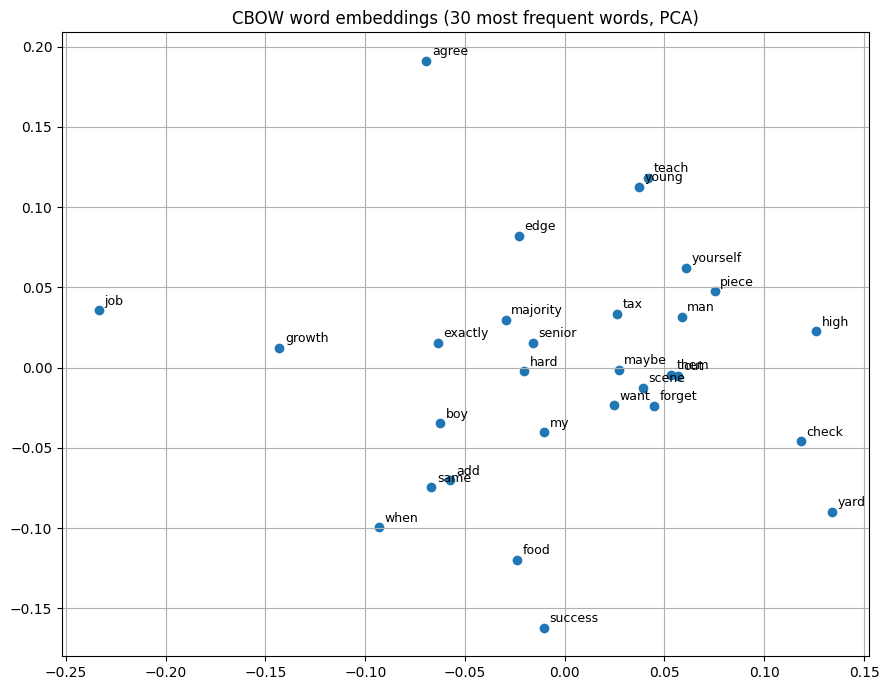

In [ ]:
import matplotlib.pyplot as plt
plt.figure(figsize=(9,7))
plt.scatter(coords[:, 0], coords[:, 1])
for (x,y), w in zip(coords, words):
  plt.annotate(w, (x,y), textcoords="offset points", xytext=(4,4), fontsize=9)
plt.title("CBOW word embeddings (30 most frequent words, PCA)")
plt.grid(True)
plt.tight_layout()
plt.show()